# RNA-seq analysis: GEO GSE107011

Real public deposited bulk RNA-seq TPM data from Monaco et al. (2019), PMID 30726743, DOI 10.1016/j.celrep.2019.01.041. This is a new retrospective secondary analysis, not a reproduction of the paper’s entire deconvolution study. Original authors retain credit for generating the data.

## Setup

Run from the repository root after installing `requirements.lock`. The validation runner executes this notebook and retains a separate executed copy. All code blocks below run against the same versioned implementation.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import analysis

OUT = Path("artifacts/run")

## 1. Acquire and reconcile

Download the expression matrix, GEO sample metadata, and PubMed MEDLINE record using pinned source hashes. Match TPM column names to GEO titles by an explicit suffix rule, and require one-to-one IDs, exact sample sets, finite nonnegative values and consistent cell-type fields. Biopython parses the publication metadata; it is not a single-cell analysis library.

## 2. Quality checks and descriptive analysis

Report sample counts, donor counts, cell-type coverage, detected genes and total deposited TPM. Exclude PBMC mixtures and require at least three donors per included cell type, independent of model results. Apply log2(TPM+1), not a second raw-count normalization. PCA is exploratory and fitted on all included samples; it is never used as validation evidence.

## 3. Evaluate without donor leakage

Leave one donor out at a time. Every training fold independently fits variance filtering, ANOVA feature selection, scaling and logistic regression. Compare against a dummy baseline and a sample-level split. Report every fold and its donor overlap. Cell-type classification within four donors does not validate use in new cohorts, patients, diseases or clinical workflows.

## 4. Exact paired contrast

Compare NK cells with naive B cells within the same four donors using log2(TPM+1) differences. Enumerate all 16 sign flips. The minimum attainable two-sided exact p-value is 2/16 = 0.125. Apply Benjamini-Hochberg correction across tested genes, and distinguish descriptive effect sizes from statistical discoveries. These are exploratory transformed-expression contrasts, not raw-count differential expression with DESeq2/edgeR.

## Execute the complete analysis

Inspect the returned results and tables. No outcome is hand-written into the code or edited to create a better story.

In [2]:
summary = analysis.run(OUT)
print(json.dumps(summary, indent=2))

<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
<python-env>/lib/python3.13/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  ys_types = set(type_of_target(x) for x in ys)
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique class

<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
<python-env>/lib/python3.13/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  ys_types = set(type_of_target(x) for x in ys)
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique class

<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The numbe

<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  ys_types = set(type_of_target(x) for x in ys)
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique class

<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  ys_types = set(type_of_target(x) for x in ys)
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique class

...

<python-env>/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
 

<python-env>/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
 

<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  ys_types = set(type_of_target(x) for x in ys)
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique class

<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
<python-env>/lib/python3.13/site-packages/sklearn/metrics/_classification.py:99: UserWarning: The numbe

{
  "dataset": "GSE107011",
  "source_samples": 127,
  "source_genes": 58311,
  "source_donors": 13,
  "included_samples": 112,
  "included_donors": 4,
  "included_cell_types": 28,
  "excluded_samples": [
    {
      "sample_id": "925L_CD4_TE",
      "cell_type": "Terminal effector CD4 T cells"
    },
    {
      "sample_id": "9JD4_CD4_TE",
      "cell_type": "Terminal effector CD4 T cells"
    },
    {
      "sample_id": "CYFZ_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id": "FY2H_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id": "FLWA_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id": "453W_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id": "684C_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id": "CZJE_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id": "DZQV_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id": "925L_PBMC",
      "cell_type": "PBMCs"
    },
    {
      "sample_id"

,sample_id,sum_TPM,detected_genes,included,cell_type
0,DZQV_CD8_naive,9.999998e+05,25939,True,Naive CD8 T cells
1,DZQV_CD8_CM,9.999998e+05,25663,True,Central memory CD8 T cell
2,DZQV_CD8_EM,1.000000e+06,25443,True,Effector memory CD8 T cells
3,DZQV_CD8_TE,1.000000e+06,26421,True,Terminal effector CD8 T cells
4,DZQV_MAIT,1.000000e+06,25214,True,MAIT cells


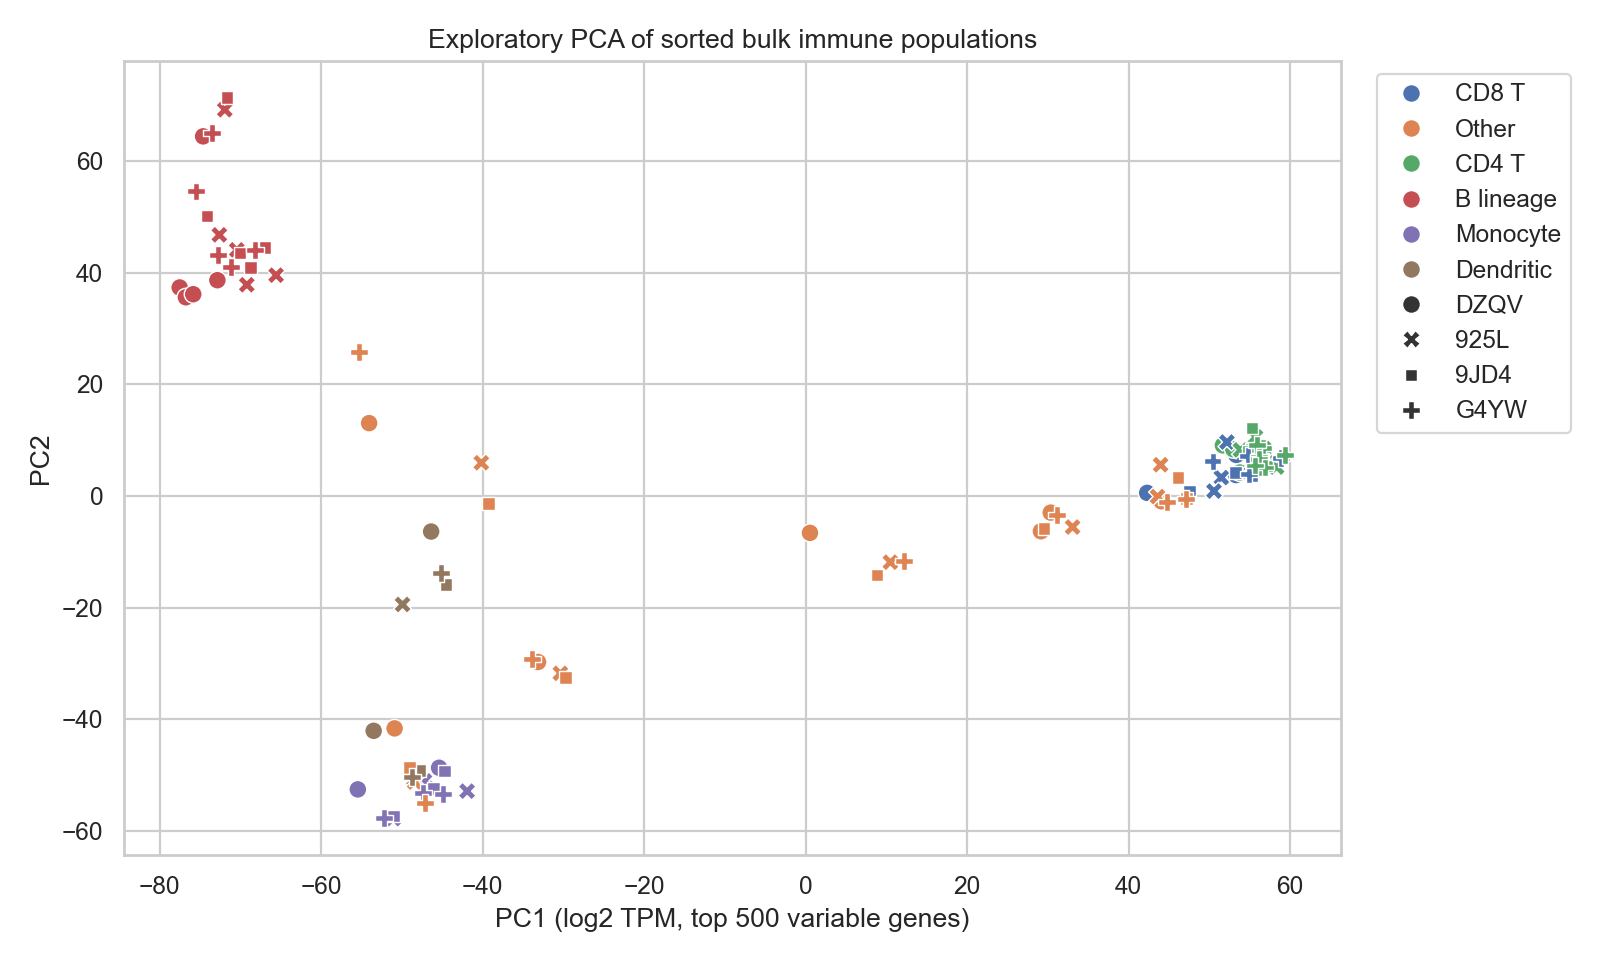

In [3]:
display(pd.read_csv(OUT / "quality_control.csv").head())
display(Image(filename=str(OUT / "pca.png")))

,fold,n_train,n_test,overlapping_donors,accuracy,macro_f1
0,0,84,28,0,0.928571,0.916667
1,1,84,28,0,0.892857,0.869048
2,2,84,28,0,0.928571,0.904762
3,3,84,28,0,0.964286,0.952381


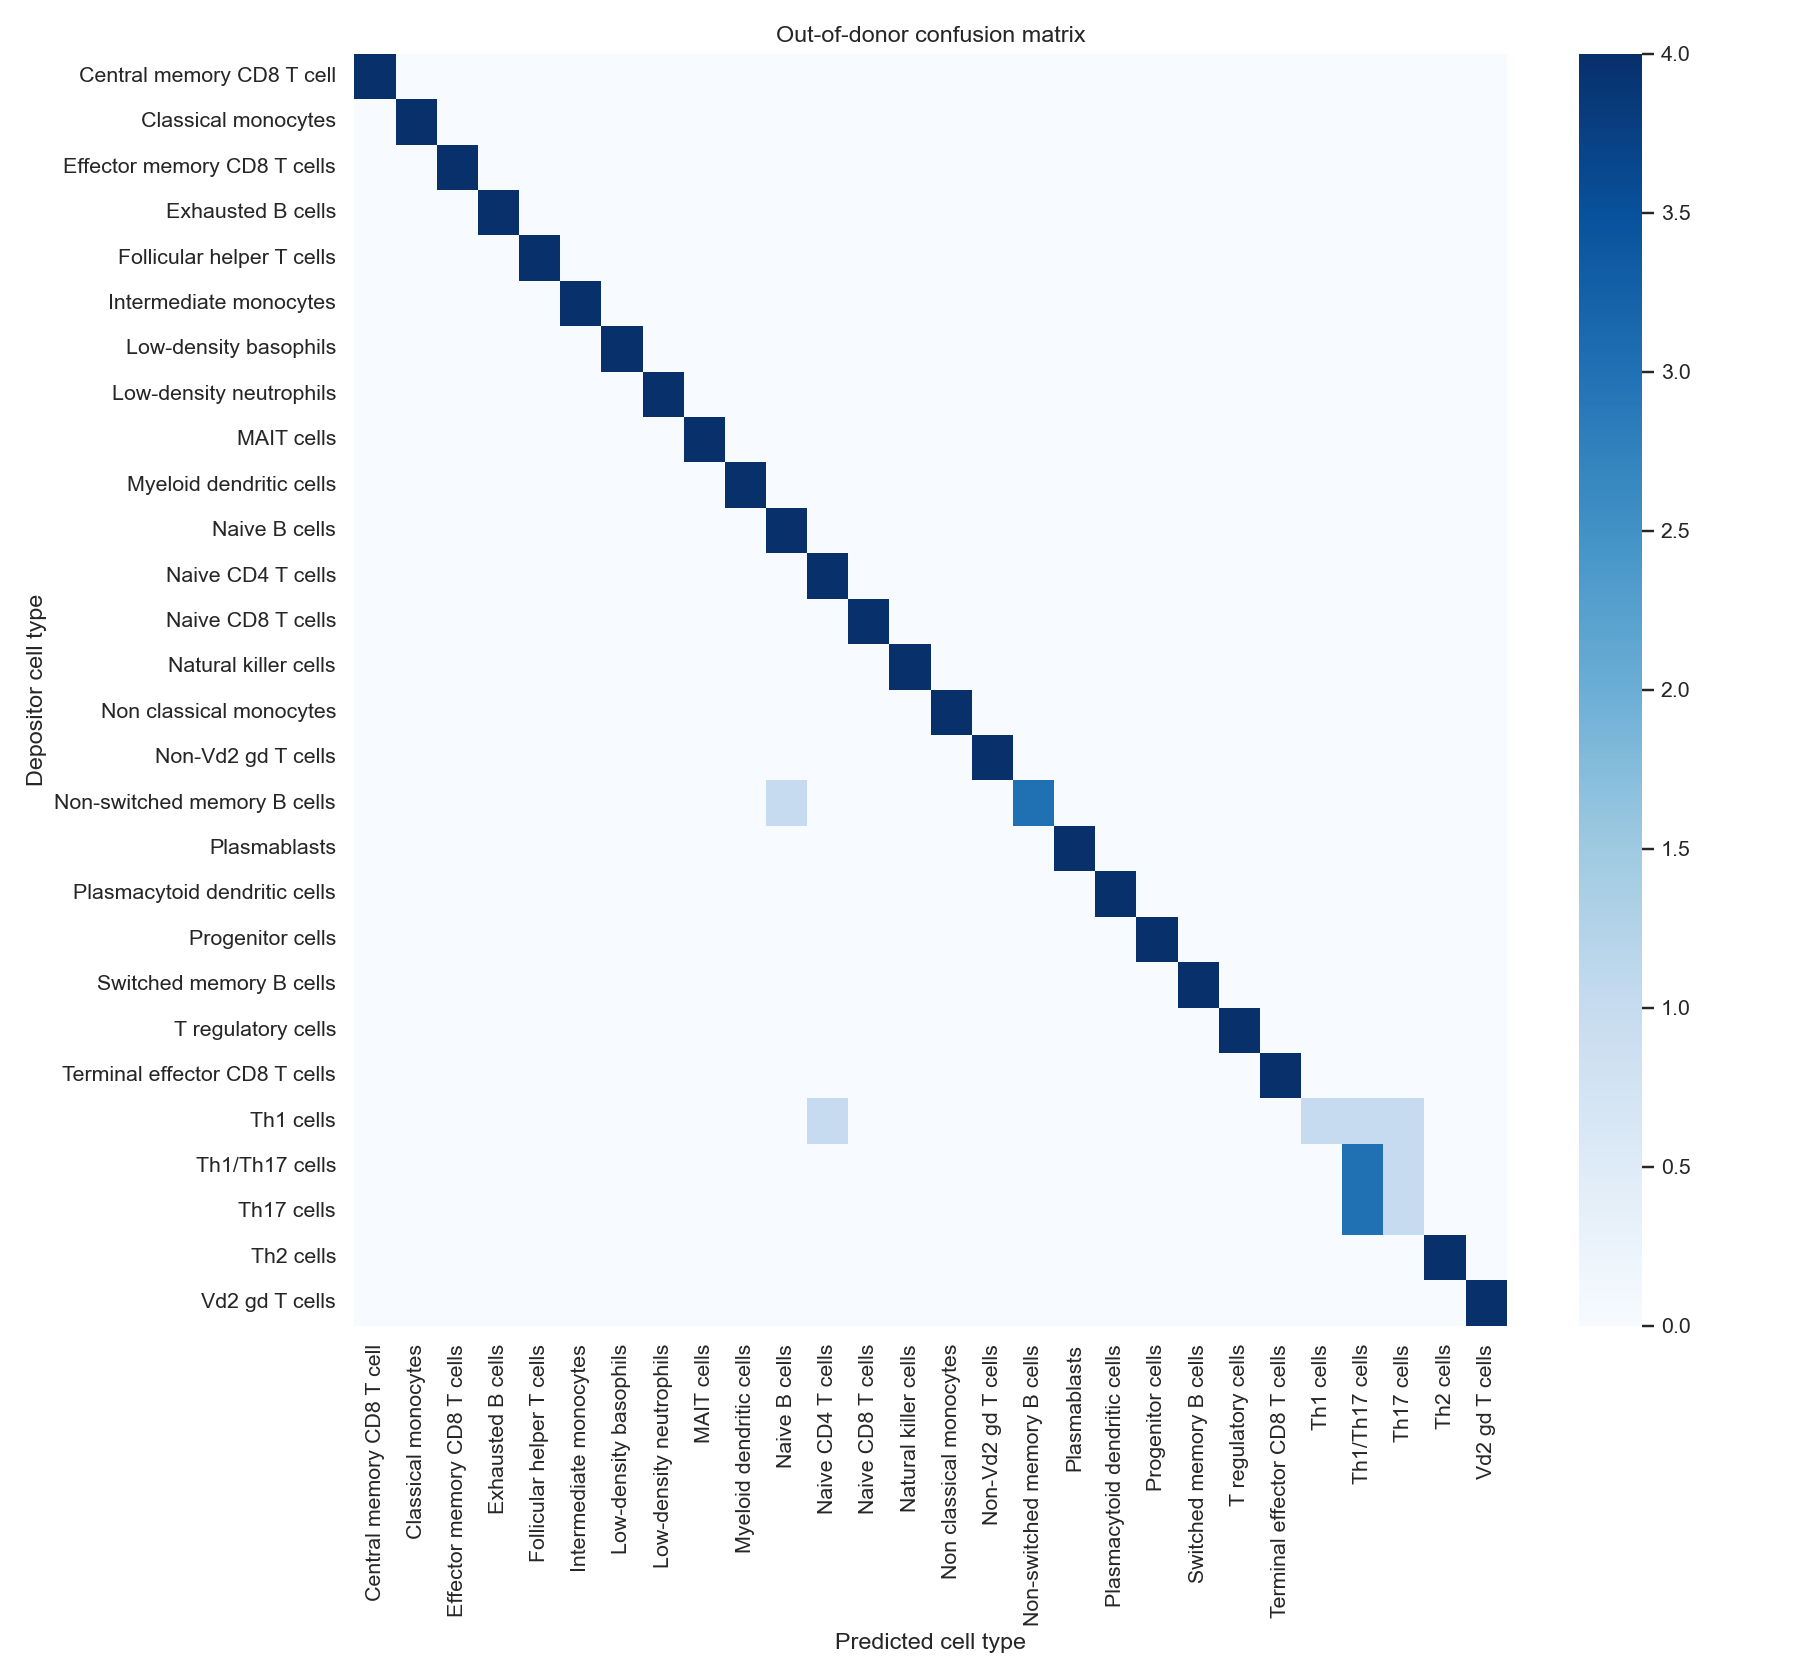

In [4]:
display(pd.read_csv(OUT / "donor_holdout_scores.csv"))
display(Image(filename=str(OUT / "confusion_matrix.png")))

,gene_id,mean_paired_log2_TPM_plus1_difference,exact_sign_flip_p,BH_q
22985,ENSG00000282173.1,9.170603,0.125,0.664679
37927,ENSG00000211825.1,9.170153,0.125,0.664679
22983,ENSG00000282133.1,8.154309,0.125,0.664679
22986,ENSG00000282780.1,8.141200,0.125,0.664679
6586,ENSG00000115523.16,7.391172,0.125,0.664679
37930,ENSG00000211828.1,7.374184,0.125,0.664679
29009,ENSG00000180644.7,7.177987,0.125,0.664679
49295,ENSG00000180739.13,7.161448,0.125,0.664679
37931,ENSG00000211829.9,7.061787,0.125,0.664679
37921,ENSG00000251002.7,6.969365,0.125,0.664679


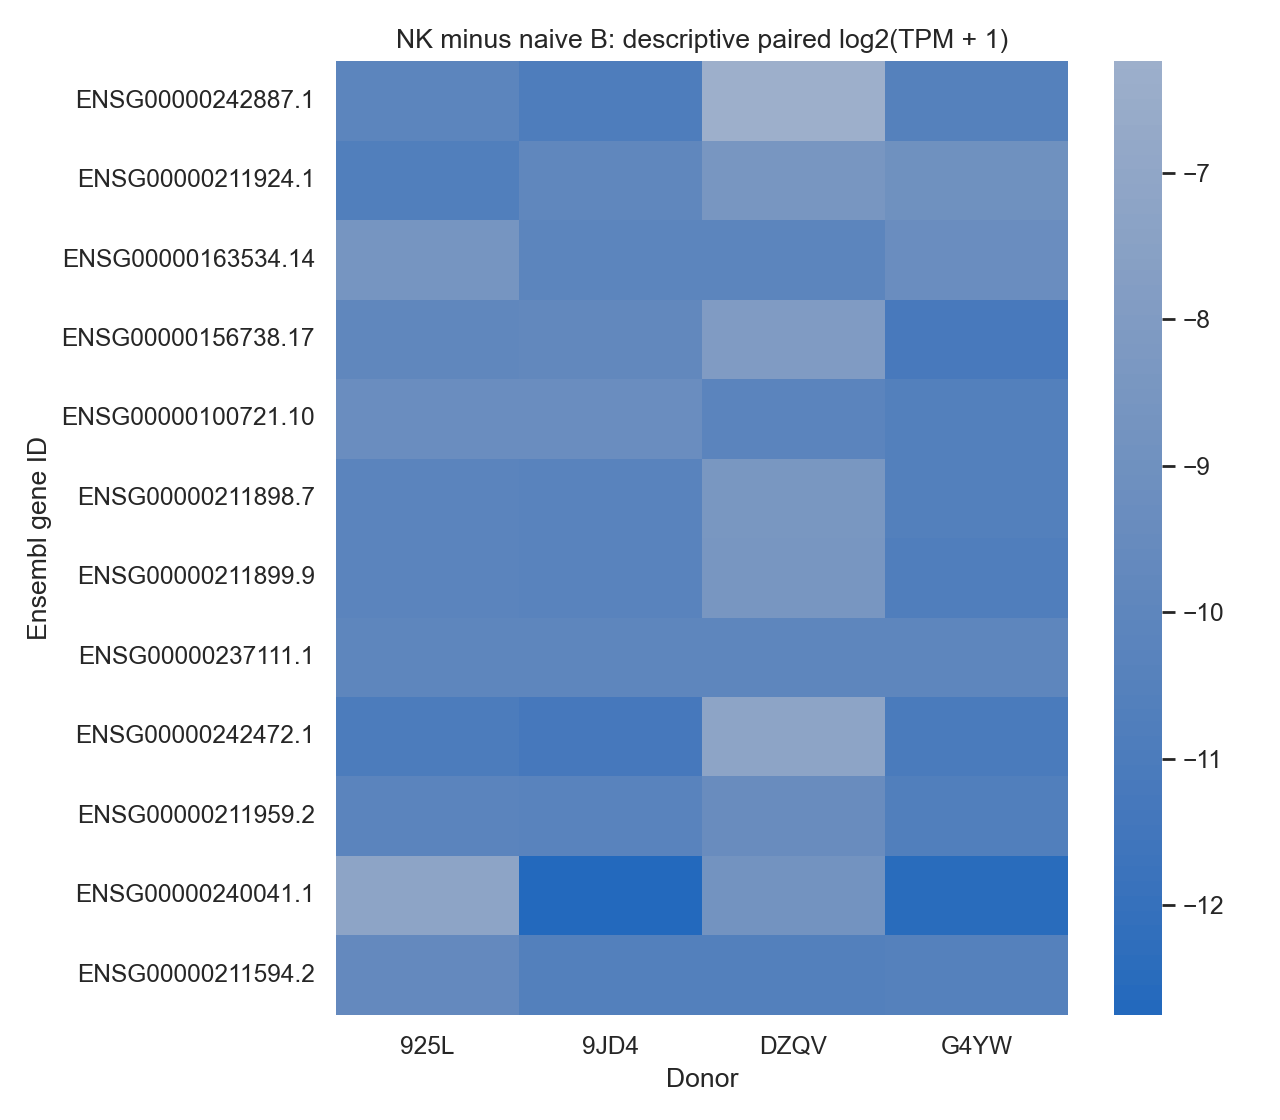

In [5]:
contrast = pd.read_csv(OUT / "paired_NK_vs_naive_B.csv")
display(
    contrast.sort_values("mean_paired_log2_TPM_plus1_difference", ascending=False).head(
        10
    )
)
display(Image(filename=str(OUT / "paired_contrast.png")))

## 5. Negative control

Shuffle the cell-type labels, keeping class counts, and repeat the donor-held-out evaluation twenty times. A leak-free pipeline should fall to chance. Selecting features on all samples first should not.

,seed,in_fold_accuracy,selection_outside_folds_accuracy
mean,9.5,0.010714,0.570982
max,19.0,0.035714,0.696429


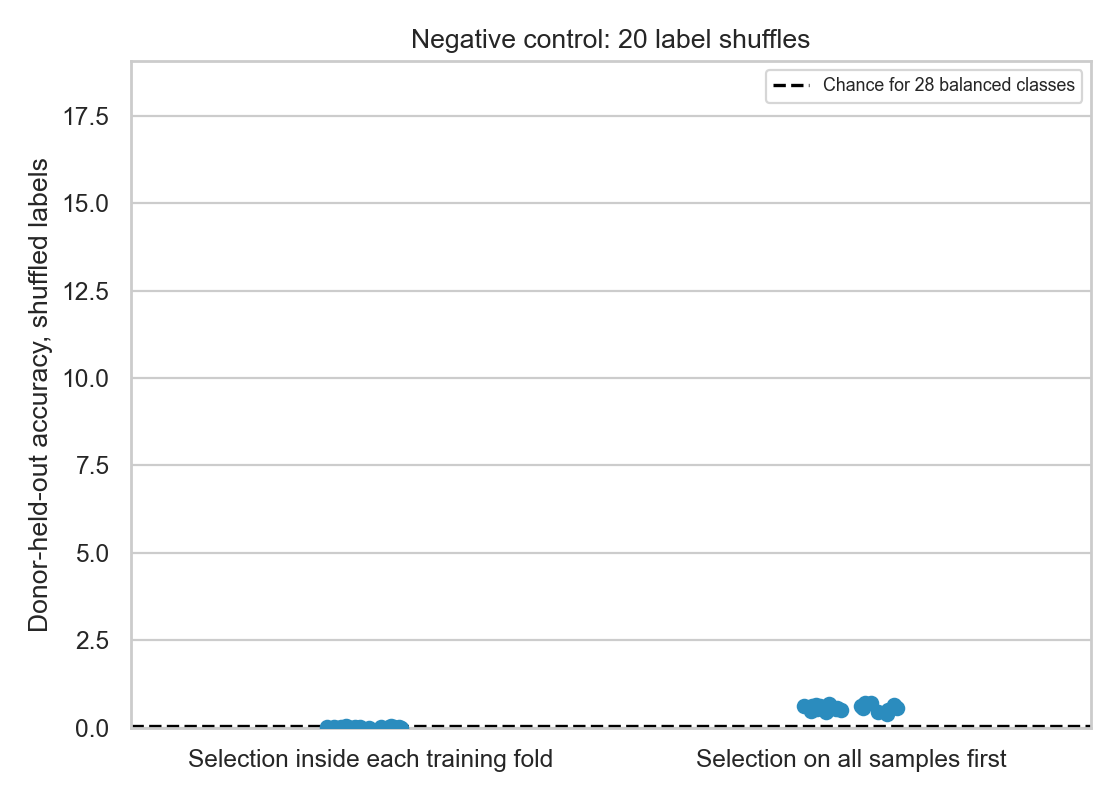

In [6]:
display(pd.read_csv(OUT / "permutation_control.csv").describe().loc[["mean", "max"]])
display(Image(filename=str(OUT / "permutation_control.png")))

## What was validated

`tests/` checks hand-calculated examples, independent formulations, malformed inputs and relevant invariants. `python scripts/validate.py` runs pytest, the full pipeline and this notebook. Passing these checks is bounded computational evidence, not clinical validation. See `reports/reference/FINDINGS.md` for actual results and limitations.